# Dual FEG: residual decay for monotone Lipschitz operators

Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $R\geq0$, $A(x_\star)=0$ and $\|x_{0}-x_\star\|^2\leq R^2$. For a fixed integer $N\geq1$, set $z_{0}=0$ and $\alpha=1/L$. For $k=0,\ldots,N-1$, run
$$x_{k+1/2}=x_{k}-\alpha z_{k}-\alpha A(x_{k}),$$
$$x_{k+1}=x_{k+1/2}-\frac{N-k-1}{N-k}\alpha\bigl(A(x_{k+1/2})-A(x_{k})\bigr),$$
$$z_{k+1}=\frac{N-k-1}{N-k}z_{k}-\frac{A(x_{k+1/2})}{N-k}.$$
We select $\|A(x_{N})\|^2$ as the performance metric. The bound proved below is $4L^2R^2/N^2$. Pairwise monotonicity and Lipschitz inequalities define the PEP relaxation; numerical values alone do not prove an arbitrary-horizon theorem.


## Proof Statement

### Theorem
Under the stated assumptions, for every integer $N\geq1$ the given dual FEG algorithm satisfies
$$\boxed{\|A(x_{N})\|^2\leq\frac{4L^2R^2}{N^2}.}$$
An exact terminal-dependent Lyapunov certificate is obtained by writing $g=A(x_{N})$, $a=x_{0}-x_{N}$, $b_{k}=x_{k}-x_{N}$ and defining, for $0\leq k<N$,
$$V_{k}=-\frac{4L}{N}\langle g,a\rangle+\frac{4L}{N-k}\langle g,b_{k}\rangle-4\langle g,z_{k}\rangle+\frac{4L}{N-k}\langle b_{k},z_{k}\rangle-2\|z_{k}\|^2,$$
with the separate terminal expression
$$V_{N}=2\|g\|^2-\frac{4L}{N}\langle g,a\rangle.$$
Then $V_{0}=0$ and $V_{k+1}\leq V_{k}$ for every step. The certificate uses the terminal point as an anchor; it is not required to be positive. The rate bound is valid, but not tight at $N=1$ according to the numerical PEP evidence.


### Proof outline
Define the nonpositive residuals
$$\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2\leq0,\qquad
\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle\leq0.$$
For $g=A(x_{N})$, $a=x_{0}-x_{N}$ and $b_{k}=x_{k}-x_{N}$, use
$$V_{k}=-\frac{4L}{N}\langle g,a\rangle+\frac{4L}{N-k}\langle g,b_{k}\rangle-4\langle g,z_{k}\rangle+\frac{4L}{N-k}\langle b_{k},z_{k}\rangle-2\|z_{k}\|^2\quad(0\leq k<N),$$
and $V_{N}=2\|g\|^2-\frac{4L}{N}\langle g,a\rangle$. Since $z_{0}=0$ and $b_{0}=a$, $V_{0}=0$.

For $0\leq k\leq N-2$, put $t=N-k\geq2$. Substituting the algorithm's two updates gives the exact identity
$$V_{k+1}-V_{k}=\frac{2}{t^2}\operatorname{Lip}(x_{k},x_{k+1/2})+\frac{4L}{t(t-1)}\operatorname{Mon}(x_{k+1/2},x_{N})\leq0.$$
At the last step, $x_{N}=x_{N-1/2}=x_{N-1}-[z_{N-1}+A(x_{N-1})]/L$, and
$$V_{N}-V_{N-1}=2\operatorname{Lip}(x_{N-1},x_{N})\leq0.$$
These coefficients are positive on their stated domains. Thus $V_{N}\leq V_{0}=0$. For $N=1$, there are no interior steps; the last-step identity applies directly with $z_{0}=0$.

Finally, $A(x_{\star})=0$ gives the exact boundary identity
$$\begin{aligned}
\|g\|^2-\frac{4L^2R^2}{N^2}
={}&V_{N}+\frac{4L}{N}\operatorname{Mon}(x_{N},x_{\star})
-\left\|g-\frac{2L}{N}(x_{0}-x_{\star})\right\|^2\\
&+\frac{4L^2}{N^2}\bigl(\|x_{0}-x_{\star}\|^2-R^2\bigr).
\end{aligned}$$
Each term on the right is nonpositive: use the decrease just proved, monotonicity, nonnegativity of a squared norm, and the initial condition. This proves the stated bound, including $R=0$, without dividing by $R$ or $\|g\|$. The exact symbolic checks below cover Gram, function-value and constant components separately.


In [1]:
import sys
from pathlib import Path

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [
    str(repo_root),
    str(notebook_dir / "supplementary" / "helpers"),
    str(notebook_dir),
]

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pepflow as pf
import sympy as sp

assert Path(pf.__file__).resolve().is_relative_to(repo_root)
print("Framework origin:", pf.__file__)

Framework origin: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r04\supplementary\approved\pepflow\__init__.py


## Operator and parameter definitions

In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)

## Algorithm and performance estimation setup

In [4]:
def make_ctx_dual_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    z = pf.Vector.zero().add_tag("z_0")
    for k in range(int(N)):
        t = sp.Integer(N - k)
        g = A(x)
        half = (x - z / L - g / L).add_tag(f"x_{k}_half")
        gh = A(half)
        x = (half - (t - 1) / t / L * (gh - g)).add_tag(f"x_{k + 1}")
        z = ((t - 1) / t * z - gh / t).add_tag(f"z_{k + 1}")
    A(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_dual_feg(f"dual_feg_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A

In [5]:
ctx_check, pb_check, operator_check = get_pep_setup(2, {"L": 1, "R": 1})
print("Setup constructed; terminal metric:", pb_check.performance_metric)

Setup constructed; terminal metric: |A(x_2)|^2


## Numerical evidence
The saved sweep uses CLARABEL with its default options, $L=R=1$, and one solve for each $N=1,\ldots,7$. The inverse-square candidate agrees with $N=2,\ldots,7$; at $N=1$ the relaxation gives $2$ rather than $4$. Scaling $A$ by $L$ and the coordinates by $R$ motivates the factor $L^2R^2$ (the $R=0$ case starts at a zero). The exact proof appears in the symbolic sections below.


N=1: PEP=1.9999999863, candidate=4.0000000000, status=optimal
N=2: PEP=1.0000000101, candidate=1.0000000000, status=optimal
N=3: PEP=0.4444444527, candidate=0.4444444444, status=optimal
N=4: PEP=0.2500000041, candidate=0.2500000000, status=optimal
N=5: PEP=0.1600000028, candidate=0.1600000000, status=optimal
N=6: PEP=0.1111111153, candidate=0.1111111111, status=optimal
N=7: PEP=0.0816326558, candidate=0.0816326531, status=optimal
Maximum absolute discrepancy for N>=2: 1.0076352419119416e-08


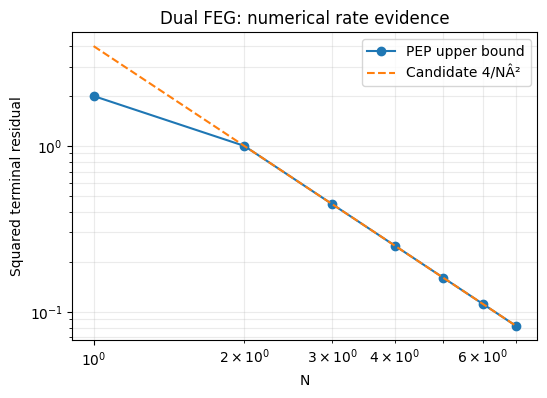

In [6]:
state = json.loads((notebook_dir / "state" / "dual_feg_b1.json").read_text())
rows = state["sweep_results"]
ns = np.array([r["N"] for r in rows])
values = np.array([r["opt_value"] for r in rows])
candidate = 4.0 / ns**2
for r, guess in zip(rows, candidate):
    print(
        f"N={r['N']}: PEP={r['opt_value']:.10f}, candidate={guess:.10f}, status={r['solver_status']}"
    )
print(
    "Maximum absolute discrepancy for N>=2:", np.max(np.abs(values[1:] - candidate[1:]))
)
assert np.max(np.abs(values[1:] - candidate[1:])) < 1e-5
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ns, values, "o-", label="PEP upper bound")
ax.loglog(ns, candidate, "--", label="Candidate 4/NÂ²")
ax.set(
    xlabel="N",
    ylabel="Squared terminal residual",
    title="Dual FEG: numerical rate evidence",
)
ax.legend()
ax.grid(True, which="both", alpha=0.25)
plt.show()

## Dense and relaxed proof solves
At $N=6$, the dense solve and both sparsity tests use CLARABEL defaults. The first test drops multipliers below $10^{-6}$. Because $x_{N-1/2}=x_{N}$, redundant final evaluation constraints yield nonunique coefficients. The selected pattern retains monotonicity between $x_{k+1/2}$ and $x_{N}$ for $k<N-1$, terminal-root monotonicity, and Lipschitz inequalities between $x_{k}$ and $x_{k+1/2}$ (using the terminal point at the last step). Each saved certificate contains all retained multipliers and its own $S$ from the same solve.


In [7]:
dense_summary = json.loads((notebook_dir / "state" / "dual_feg_dense.json").read_text())
threshold_summary = json.loads(
    (notebook_dir / "supplementary" / "b2-selected-raw.json").read_text()
)
sparse_summary = json.loads(
    (notebook_dir / "supplementary" / "b2-selected-structural.json").read_text()
)
for name, sample in [
    ("dense", dense_summary),
    ("threshold", threshold_summary),
    ("structural", sparse_summary),
]:
    print(
        name,
        "bound:",
        sample["opt_value"],
        "solver:",
        sample["certificate_provenance"]["solver"],
    )
    for group in sample["lambda_groups"]:
        active = [
            (key, val)
            for key, val in sample["named_dual_values"].items()
            if val is not None
            and abs(val) > 1e-6
            and sample["constraint_metadata"][key]["group"] == group
        ]
        print(group, "active count:", len(active))
        print(active)
    print(
        "S rank at absolute tolerance 1e-4:",
        np.linalg.matrix_rank(np.array(sample["S_matrix"]), tol=1e-4),
    )
print("Basis:", sparse_summary["basis_vectors"])
print(
    "Dense-to-selected bound difference:",
    abs(dense_summary["opt_value"] - sparse_summary["opt_value"]),
)

dense bound: 0.11111111529546581 solver: {'api': 'CVXPrimalSolver.build_problem', 'effective_name': 'CLARABEL', 'settings': {'solver': 'CLARABEL'}, 'failures': []}
Monotone Operator Inequality active count: 13
[('A monotone:x_0_half,x_5_half', 8.239340761584955e-06), ('A monotone:x_0_half,x_6', 0.1333253492566433), ('A monotone:x_1_half,x_5_half', 1.8955811066667154e-05), ('A monotone:x_1_half,x_6', 0.19998141550695986), ('A monotone:x_2_half,x_5_half', 3.073100759722682e-05), ('A monotone:x_2_half,x_6', 0.3333032013104182), ('A monotone:x_3_half,x_5_half', 3.9532223980800914e-05), ('A monotone:x_3_half,x_6', 0.666628325005781), ('A monotone:x_4_half,x_5_half', 8.966290891704228e-05), ('A monotone:x_4_half,x_6', 1.9999138906452372), ('A monotone:x_5_half,x_6', 0.22327137706274558), ('A monotone:x_5_half,x_star', 5.820733713134451e-05), ('A monotone:x_6,x_star', 0.6666096567133383)]
Lipschitz Continuous Inequality active count: 8
[('A Lipschitz:x_0,x_0_half', 0.05555566632590544), ('A L

## Lambda and S verification
For normalized $L=R=1$, the initial search suggests $\tau=4/N^2$, terminal-root multiplier $4/N$, half-step-to-terminal monotonicity multipliers $4/[(N-k)(N-k-1)]$ for $k<N-1$, and within-step Lipschitz multipliers $2/(N-k)^2$. The candidate remainder is
$$S_{\mathrm{guess}}=\left\|\frac{2}{N}(x_{0}-x_\star)-A(x_{N})\right\|^2.$$
These formulas are **fixed-sample candidates**, not an all-horizon analytic proof. The authoritative handoff retains the original numerical multipliers and remainder. Reverse LDL retains every factor and off-diagonal block, with a reconstruction check. The complete identity checked below is
$$\|A(x_{N})\|^2-\mathrm{bound}-\sum_{i}\lambda_{i} R_{i}+S=0,$$
where every scalar residual is normalized as $R_{i}\leq0$. Nonnegative multipliers and $S\succeq0$ establish the numerical certificate direction. No PSD constraint families or function-value terms occur for this setup; their absence is checked explicitly. At this discovery stage both analytic statuses were unverified. The final local Lyapunov proof is established below; the global full-PEP formula remains a numerical candidate.


In [8]:
# B2 mathematical checks, also embedded verbatim in the notebook.
import hashlib
import json
from fractions import Fraction

import numpy as np
import pepflow as pf
from pepflow.lyapunov_utils import ldl_decompose_with_reversed_basis
from certificate_tools import source_hashes  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

b1 = json.loads((notebook_dir / "state" / "dual_feg_b1.json").read_text())
dense = json.loads((notebook_dir / "state" / "dual_feg_dense.json").read_text())
selected = json.loads(
    (notebook_dir / "supplementary" / "b2-selected-structural.json").read_text()
)
N = selected["N"]
ctx, pb, obj = get_pep_setup(N, {"L": 1, "R": 1})
pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
groups = ctx.get_constraint_data(obj)
entries = [(c, "initial", None, None) for c in pb.init_conditions]
entries.extend(
    (c, "interpolation", str(obj), str(group))
    for group, constraints in groups.sc_dict.items()
    for c in constraints
)
assert not groups.psd_dict and not ctx.func_to_triplets
assert set(selected["named_dual_values"]) == {c.name for c, *_ in entries}
assert selected["certificate_provenance"]["source_hashes"] == source_hashes(
    notebook_dir
)
basis = ctx.basis_vectors()
labels = [str(v) for v in basis]
assert (
    labels
    == selected["basis_vectors"]
    == selected["S_row_names"]
    == selected["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == selected["basis_scalars"]
assert selected["tau_name"] == "initial_condition"
S_array = np.asarray(selected["S_matrix"], dtype=float)
S_sol = pf.MatrixWithNames(S_array, labels, labels)
D, ell = ldl_decompose_with_reversed_basis(S_sol, basis, print_output=False)
E = np.asarray([pm.eval_vector(v).coords for v in ell], dtype=float)
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
weighted = pf.Scalar.zero()
inequality_values = []
for c, origin, owner, group in entries:
    meta = selected["constraint_metadata"][c.name]
    assert (
        meta["origin"] == origin and meta["owner"] == owner and meta["group"] == group
    )
    assert (
        meta["comparator"] == c.cmp.value
        and meta["kind"] == "scalar"
        and meta["shape"] == []
    )
    value = selected["named_dual_values"][c.name]
    if meta["relaxed"]:
        assert c.name in selected["relaxed_constraints"] and value is None
        continue
    assert value is not None and np.isfinite(value)
    assert c.cmp.value == "LE"
    weighted += value * (c.lhs - c.rhs)
    inequality_values.append(value)
checked = pm.eval_scalar(
    pb.performance_metric - selected["opt_value"] - weighted + S_numeric
)


def max_abs(value):
    return float(np.max(np.abs(np.asarray(value, dtype=float)), initial=0.0))


residuals = {
    "identity_gram_max_abs": max_abs(checked.inner_prod_coords),
    "identity_func_max_abs": max_abs(checked.func_coords),
    "identity_offset_abs": max_abs(checked.offset),
    "S_reconstruction_max_abs": max_abs(E.T @ D @ E - S_array),
    "dense_relaxed_gap": abs(dense["opt_value"] - selected["opt_value"]),
    "minimum_scalar_inequality_dual": min(inequality_values),
    "minimum_S_eigenvalue": float(np.linalg.eigvalsh(S_array).min()),
    "minimum_matrix_inequality_eigenvalue": 0.0,
    "conjecture_gap": abs(selected["opt_value"] - 4 / N**2),
}
tolerances = dict(
    identity_atol=1e-5,
    identity_rtol=0,
    reconstruction_atol=1e-4,
    reconstruction_rtol=1e-5,
    dual_tol=1e-6,
    psd_tol=1e-6,
    dense_opt_atol=1e-5,
)
assert selected["certificate_provenance"]["solver_status"] == "optimal"
assert np.isfinite(S_array).all() and np.allclose(S_array, S_array.T, atol=1e-6, rtol=0)
assert all(
    residuals[key] <= 1e-5
    for key in ("identity_gram_max_abs", "identity_func_max_abs", "identity_offset_abs")
)
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
assert residuals["dense_relaxed_gap"] < 1e-5 and residuals["conjecture_gap"] < 1e-5
assert residuals["minimum_scalar_inequality_dual"] >= -1e-6
assert residuals["minimum_S_eigenvalue"] >= -1e-6
print("Numerical certificate checks:", json.dumps(residuals, indent=2))
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(checked.inner_prod_coords, dtype=float), labels, labels
    )
)
print("Reverse LDL diagonal:", np.diag(D))
pf.pprint_labeled_matrix(pf.MatrixWithNames(E.T @ D @ E, labels, labels))

# Initial closed-form attempt: terminal-star monotonicity and within-step Lipschitz.
# These are candidate formulas, verified here only at the selected fixed horizon.
candidate = {"initial_condition": 4 / N**2, f"A monotone:x_{N},x_star": 4 / N}
for k in range(N - 1):
    t = N - k
    candidate[f"A monotone:x_{k}_half,x_{N}"] = 4 / (t * (t - 1))
    candidate[f"A Lipschitz:x_{k},x_{k}_half"] = 2 / t**2
candidate[f"A Lipschitz:x_{N - 1},x_{N}"] = 2
lambda_error = max(
    abs(selected["named_dual_values"][name] - value)
    for name, value in candidate.items()
)
assert set(candidate) == {
    name
    for name, meta in selected["constraint_metadata"].items()
    if not meta["relaxed"]
}
assert lambda_error < 1e-4
square = (2 / N * (ctx["x_0"] - ctx["x_star"]) - obj(ctx[f"x_{N}"])) ** 2
square_eval = pm.eval_scalar(square)
S_error = max_abs(square_eval.inner_prod_coords - S_array)
assert (
    S_error < 1e-4
    and max_abs(square_eval.func_coords) == 0
    and max_abs(square_eval.offset) == 0
)
candidate_weighted = sum(
    (candidate.get(c.name, 0.0) * (c.lhs - c.rhs) for c, *_ in entries),
    pf.Scalar.zero(),
)
candidate_identity = pm.eval_scalar(
    pb.performance_metric - 4 / N**2 - candidate_weighted + square
)
candidate_residual = max(
    max_abs(candidate_identity.inner_prod_coords),
    max_abs(candidate_identity.func_coords),
    max_abs(candidate_identity.offset),
)
assert candidate_residual < 1e-5
for name, value in candidate.items():
    print(
        name,
        "numerical",
        selected["named_dual_values"][name],
        "candidate",
        Fraction(value).limit_denominator(1000),
    )
print(
    "Candidate lambda error:",
    lambda_error,
    "Candidate S error:",
    S_error,
    "Fixed-N identity residual:",
    candidate_residual,
)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(square_eval.inner_prod_coords, dtype=float), labels, labels
    )
)

state_b2 = {
    **b1,
    **selected,
    "normalization": {
        "tau_name": "initial_condition",
        "initial_condition": b1["initial_condition"],
        "performance_metric": b1["performance_metric"],
        "bound_value": selected["opt_value"],
        "bound_formula": b1["conjectured_rate"],
    },
    "numerical_checks": {
        "tolerances": tolerances,
        "residuals": residuals,
        "passed": True,
    },
    "numerical_decomposition": {
        "method": "reverse_ldl",
        "D": D.tolist(),
        "ell_coords": E.tolist(),
        "basis_labels": labels,
    },
    "formula_status": {"lambda": "candidate", "S": "candidate"},
    "closed_form_search": {
        "completed": True,
        "references_reviewed": [
            "Own B1 and dense/threshold/structural B2 results; external/reference examples excluded by clean-room policy"
        ],
        "attempts": [
            {
                "method": "Threshold lambda at 1e-6",
                "outcome": "Preserved bound; terminal duplicate evaluations obscure formulas",
            },
            {
                "method": "Terminal-star monotonicity and within-step Lipschitz constraint pattern",
                "outcome": "Preserved bound with 12 interpolation constraints",
            },
            {
                "method": "Rational reconstruction in t=N-k",
                "outcome": "lambda candidates 4/[t(t-1)], 2/t^2, terminal-root 4/N for L=R=1",
                "max_error": lambda_error,
            },
            {
                "method": "Rank-one eigenvector inspection and direct square candidate",
                "outcome": "S=((2/N)(x0-xstar)-A(xN))^2 for L=1",
                "max_error": S_error,
                "identity_residual": candidate_residual,
            },
        ],
        "unresolved_components": [
            "Arbitrary-horizon and parameter-domain proof of lambda and S formulas"
        ],
    },
    "lamb_code": "candidate = {'initial_condition': 4/N**2, f'A monotone:x_{N},x_star': 4/N}\nfor k in range(N-1):\n    t=N-k\n    candidate[f'A monotone:x_{k}_half,x_{N}']=4/(t*(t-1))\n    candidate[f'A Lipschitz:x_{k},x_{k}_half']=2/t**2\ncandidate[f'A Lipschitz:x_{N-1},x_{N}']=2",
    "S_code": "S_guess=(2/N*(ctx['x_0']-ctx['x_star'])-obj(ctx[f'x_{N}']))**2",
    "candidate_formula_domain": "L=R=1; formulas currently checked only at N=6",
    "S_decomp_type": "ldl",
    "numerical_certificate_verified": True,
    "analytic_full_pep_verified": False,
    "lyapunov_proof_verified": False,
    "require_analytic_full_pep": False,
    "proof_valid": True,
}
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
state_b2["certificate_id"] = hashlib.sha256(
    json.dumps(
        {key: state_b2[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    ).encode()
).hexdigest()
for filename in ("dual_feg_relaxed.json", "dual_feg_b2.json"):
    (notebook_dir / "state" / filename).write_text(
        json.dumps(state_b2, indent=2, allow_nan=False)
    )

Numerical certificate checks: {
  "identity_gram_max_abs": 1.8649519168148035e-09,
  "identity_func_max_abs": 0.0,
  "identity_offset_abs": 6.90246582113474e-10,
  "S_reconstruction_max_abs": 1.3877787807814457e-17,
  "dense_relaxed_gap": 4.727785316016586e-09,
  "minimum_scalar_inequality_dual": 0.055554999917130206,
  "minimum_S_eigenvalue": 1.1840123684563205e-10,
  "minimum_matrix_inequality_eigenvalue": 0.0,
  "conjecture_gap": 5.434306060703165e-10
}


<IPython.core.display.Math object>

Reverse LDL diagonal: [9.99979968e-01 5.66025040e-10 4.80103196e-10 4.90287926e-10
 5.39027890e-10 7.42647882e-10 5.04338837e-10 7.13831517e-10
 4.94710600e-10 7.70123905e-10 4.76086947e-10 7.14834824e-10
 4.66302560e-10 6.34729819e-10 6.27293042e-10]


<IPython.core.display.Math object>

initial_condition numerical 0.11111111125792708 candidate 1/9
A monotone:x_6,x_star numerical 0.6666599885118143 candidate 2/3
A monotone:x_0_half,x_6 numerical 0.1333319988504279 candidate 2/15
A Lipschitz:x_0,x_0_half numerical 0.055554999917130206 candidate 1/18
A monotone:x_1_half,x_6 numerical 0.19999799772996038 candidate 1/5
A Lipschitz:x_1,x_1_half numerical 0.07999919951283378 candidate 2/25
A monotone:x_2_half,x_6 numerical 0.3333299955790633 candidate 1/3
A Lipschitz:x_2,x_2_half numerical 0.12499874872585522 candidate 1/8
A monotone:x_3_half,x_6 numerical 0.6666599900365547 candidate 2/3
A Lipschitz:x_3,x_3_half numerical 0.22221999708714482 candidate 2/9
A monotone:x_4_half,x_6 numerical 1.99997996864752 candidate 2
A Lipschitz:x_4,x_4_half numerical 0.49999499253471785 candidate 1/2
A Lipschitz:x_5,x_6 numerical 1.9999799674858172 candidate 2
Candidate lambda error: 2.00325141828106e-05 Candidate S error: 2.0032408179493366e-05 Fixed-N identity residual: 8.326672684688674

<IPython.core.display.Math object>

### Additional coherent certificate at $N=8$
The same structural relaxation is acquired independently at $N=8$, with CLARABEL defaults. Its dense and sparse optima agree within $1.5\times10^{-9}$. The following code replays its complete numerical certificate and decomposition checks. It remains a supplementary sample; the selected main certificate is still $N=6$. The verified cross-horizon grouping appears below.

In [9]:
# B2 mathematical checks, also embedded verbatim in the notebook.
import hashlib
import json
from fractions import Fraction

import numpy as np
import pepflow as pf
from pepflow.lyapunov_utils import ldl_decompose_with_reversed_basis
from certificate_tools import source_hashes  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

b1 = json.loads((notebook_dir / "state" / "dual_feg_b1.json").read_text())
dense = json.loads((notebook_dir / "supplementary/n8/dense.json").read_text())
selected = json.loads((notebook_dir / "supplementary/n8/selected-raw.json").read_text())
N = selected["N"]
ctx, pb, obj = get_pep_setup(N, {"L": 1, "R": 1})
pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
groups = ctx.get_constraint_data(obj)
entries = [(c, "initial", None, None) for c in pb.init_conditions]
entries.extend(
    (c, "interpolation", str(obj), str(group))
    for group, constraints in groups.sc_dict.items()
    for c in constraints
)
assert not groups.psd_dict and not ctx.func_to_triplets
assert set(selected["named_dual_values"]) == {c.name for c, *_ in entries}
assert selected["certificate_provenance"]["source_hashes"] == source_hashes(
    notebook_dir
)
basis = ctx.basis_vectors()
labels = [str(v) for v in basis]
assert (
    labels
    == selected["basis_vectors"]
    == selected["S_row_names"]
    == selected["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == selected["basis_scalars"]
assert selected["tau_name"] == "initial_condition"
S_array = np.asarray(selected["S_matrix"], dtype=float)
S_sol = pf.MatrixWithNames(S_array, labels, labels)
D, ell = ldl_decompose_with_reversed_basis(S_sol, basis, print_output=False)
E = np.asarray([pm.eval_vector(v).coords for v in ell], dtype=float)
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
weighted = pf.Scalar.zero()
inequality_values = []
for c, origin, owner, group in entries:
    meta = selected["constraint_metadata"][c.name]
    assert (
        meta["origin"] == origin and meta["owner"] == owner and meta["group"] == group
    )
    assert (
        meta["comparator"] == c.cmp.value
        and meta["kind"] == "scalar"
        and meta["shape"] == []
    )
    value = selected["named_dual_values"][c.name]
    if meta["relaxed"]:
        assert c.name in selected["relaxed_constraints"] and value is None
        continue
    assert value is not None and np.isfinite(value)
    assert c.cmp.value == "LE"
    weighted += value * (c.lhs - c.rhs)
    inequality_values.append(value)
checked = pm.eval_scalar(
    pb.performance_metric - selected["opt_value"] - weighted + S_numeric
)


def max_abs(value):
    return float(np.max(np.abs(np.asarray(value, dtype=float)), initial=0.0))


residuals = {
    "identity_gram_max_abs": max_abs(checked.inner_prod_coords),
    "identity_func_max_abs": max_abs(checked.func_coords),
    "identity_offset_abs": max_abs(checked.offset),
    "S_reconstruction_max_abs": max_abs(E.T @ D @ E - S_array),
    "dense_relaxed_gap": abs(dense["opt_value"] - selected["opt_value"]),
    "minimum_scalar_inequality_dual": min(inequality_values),
    "minimum_S_eigenvalue": float(np.linalg.eigvalsh(S_array).min()),
    "minimum_matrix_inequality_eigenvalue": 0.0,
    "conjecture_gap": abs(selected["opt_value"] - 4 / N**2),
}
tolerances = dict(
    identity_atol=1e-5,
    identity_rtol=0,
    reconstruction_atol=1e-4,
    reconstruction_rtol=1e-5,
    dual_tol=1e-6,
    psd_tol=1e-6,
    dense_opt_atol=1e-5,
)
assert selected["certificate_provenance"]["solver_status"] == "optimal"
assert np.isfinite(S_array).all() and np.allclose(S_array, S_array.T, atol=1e-6, rtol=0)
assert all(
    residuals[key] <= 1e-5
    for key in ("identity_gram_max_abs", "identity_func_max_abs", "identity_offset_abs")
)
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
assert residuals["dense_relaxed_gap"] < 1e-5 and residuals["conjecture_gap"] < 1e-5
assert residuals["minimum_scalar_inequality_dual"] >= -1e-6
assert residuals["minimum_S_eigenvalue"] >= -1e-6
print("Numerical certificate checks:", json.dumps(residuals, indent=2))
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(checked.inner_prod_coords, dtype=float), labels, labels
    )
)
print("Reverse LDL diagonal:", np.diag(D))
pf.pprint_labeled_matrix(pf.MatrixWithNames(E.T @ D @ E, labels, labels))

# Initial closed-form attempt: terminal-star monotonicity and within-step Lipschitz.
# These are candidate formulas, verified here only at the selected fixed horizon.
candidate = {"initial_condition": 4 / N**2, f"A monotone:x_{N},x_star": 4 / N}
for k in range(N - 1):
    t = N - k
    candidate[f"A monotone:x_{k}_half,x_{N}"] = 4 / (t * (t - 1))
    candidate[f"A Lipschitz:x_{k},x_{k}_half"] = 2 / t**2
candidate[f"A Lipschitz:x_{N - 1},x_{N}"] = 2
lambda_error = max(
    abs(selected["named_dual_values"][name] - value)
    for name, value in candidate.items()
)
assert set(candidate) == {
    name
    for name, meta in selected["constraint_metadata"].items()
    if not meta["relaxed"]
}
assert lambda_error < 1e-4
square = (2 / N * (ctx["x_0"] - ctx["x_star"]) - obj(ctx[f"x_{N}"])) ** 2
square_eval = pm.eval_scalar(square)
S_error = max_abs(square_eval.inner_prod_coords - S_array)
assert (
    S_error < 1e-4
    and max_abs(square_eval.func_coords) == 0
    and max_abs(square_eval.offset) == 0
)
candidate_weighted = sum(
    (candidate.get(c.name, 0.0) * (c.lhs - c.rhs) for c, *_ in entries),
    pf.Scalar.zero(),
)
candidate_identity = pm.eval_scalar(
    pb.performance_metric - 4 / N**2 - candidate_weighted + square
)
candidate_residual = max(
    max_abs(candidate_identity.inner_prod_coords),
    max_abs(candidate_identity.func_coords),
    max_abs(candidate_identity.offset),
)
assert candidate_residual < 1e-5
for name, value in candidate.items():
    print(
        name,
        "numerical",
        selected["named_dual_values"][name],
        "candidate",
        Fraction(value).limit_denominator(1000),
    )
print(
    "Candidate lambda error:",
    lambda_error,
    "Candidate S error:",
    S_error,
    "Fixed-N identity residual:",
    candidate_residual,
)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(square_eval.inner_prod_coords, dtype=float), labels, labels
    )
)

state_b2 = {
    **b1,
    **selected,
    "normalization": {
        "tau_name": "initial_condition",
        "initial_condition": b1["initial_condition"],
        "performance_metric": b1["performance_metric"],
        "bound_value": selected["opt_value"],
        "bound_formula": b1["conjectured_rate"],
    },
    "numerical_checks": {
        "tolerances": tolerances,
        "residuals": residuals,
        "passed": True,
    },
    "numerical_decomposition": {
        "method": "reverse_ldl",
        "D": D.tolist(),
        "ell_coords": E.tolist(),
        "basis_labels": labels,
    },
    "formula_status": {"lambda": "candidate", "S": "candidate"},
    "closed_form_search": {
        "completed": True,
        "references_reviewed": [
            "Own B1 and dense/threshold/structural B2 results; external/reference examples excluded by clean-room policy"
        ],
        "attempts": [
            {
                "method": "Threshold lambda at 1e-6",
                "outcome": "Preserved bound; terminal duplicate evaluations obscure formulas",
            },
            {
                "method": "Terminal-star monotonicity and within-step Lipschitz constraint pattern",
                "outcome": "Preserved bound with 16 interpolation constraints",
            },
            {
                "method": "Rational reconstruction in t=N-k",
                "outcome": "lambda candidates 4/[t(t-1)], 2/t^2, terminal-root 4/N for L=R=1",
                "max_error": lambda_error,
            },
            {
                "method": "Rank-one eigenvector inspection and direct square candidate",
                "outcome": "S=((2/N)(x0-xstar)-A(xN))^2 for L=1",
                "max_error": S_error,
                "identity_residual": candidate_residual,
            },
        ],
        "unresolved_components": [
            "Arbitrary-horizon and parameter-domain proof of lambda and S formulas"
        ],
    },
    "lamb_code": "candidate = {'initial_condition': 4/N**2, f'A monotone:x_{N},x_star': 4/N}\nfor k in range(N-1):\n    t=N-k\n    candidate[f'A monotone:x_{k}_half,x_{N}']=4/(t*(t-1))\n    candidate[f'A Lipschitz:x_{k},x_{k}_half']=2/t**2\ncandidate[f'A Lipschitz:x_{N-1},x_{N}']=2",
    "S_code": "S_guess=(2/N*(ctx['x_0']-ctx['x_star'])-obj(ctx[f'x_{N}']))**2",
    "candidate_formula_domain": "L=R=1; formulas currently checked at N=6 and N=8 independently",
    "S_decomp_type": "ldl",
    "numerical_certificate_verified": True,
    "analytic_full_pep_verified": False,
    "lyapunov_proof_verified": False,
    "require_analytic_full_pep": False,
    "proof_valid": True,
}
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
state_b2["certificate_id"] = hashlib.sha256(
    json.dumps(
        {key: state_b2[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    ).encode()
).hexdigest()
for filename in ("dual_feg_relaxed.json", "dual_feg_b2.json"):
    (notebook_dir / "supplementary/n8" / filename).write_text(
        json.dumps(state_b2, indent=2, allow_nan=False)
    )

Numerical certificate checks: {
  "identity_gram_max_abs": 1.9831020412675744e-09,
  "identity_func_max_abs": 0.0,
  "identity_offset_abs": 5.196245794758525e-10,
  "S_reconstruction_max_abs": 2.0679515313825692e-25,
  "dense_relaxed_gap": 1.43754584625011e-09,
  "minimum_scalar_inequality_dual": 0.031250862159542064,
  "minimum_S_eigenvalue": 2.7073432363582835e-11,
  "minimum_matrix_inequality_eigenvalue": 0.0,
  "conjecture_gap": 1.5607748427015622e-10
}


<IPython.core.display.Math object>

Reverse LDL diagonal: [1.00005514e+00 4.22876853e-10 3.90673721e-10 4.51641931e-10
 4.49514128e-10 5.17570486e-10 4.18025115e-10 5.12811939e-10
 4.14470003e-10 4.81743580e-10 4.20705585e-10 5.00921305e-10
 3.94317800e-10 5.41503630e-10 3.05046267e-10 4.28677002e-10
 1.73283567e-10 4.82110026e-10 4.74832507e-10]


<IPython.core.display.Math object>

initial_condition numerical 0.0625000003635471 candidate 1/16
A monotone:x_8,x_star numerical 0.5000137830676682 candidate 1/2
A monotone:x_0_half,x_8 numerical 0.07143054140001173 candidate 1/14
A Lipschitz:x_0,x_0_half numerical 0.031250862159542064 candidate 1/32
A monotone:x_1_half,x_8 numerical 0.09524072143944462 candidate 2/21
A Lipschitz:x_1,x_1_half numerical 0.040817452322471394 candidate 2/49
A monotone:x_2_half,x_8 numerical 0.13333700972190446 candidate 2/15
A Lipschitz:x_2,x_2_half numerical 0.055557087585747005 candidate 1/18
A monotone:x_3_half,x_8 numerical 0.2000055142967839 candidate 1/5
A Lipschitz:x_3,x_3_half numerical 0.08000220589976724 candidate 2/25
A monotone:x_4_half,x_8 numerical 0.333342523404396 candidate 1/3
A Lipschitz:x_4,x_4_half numerical 0.12500344650853795 candidate 1/8
A monotone:x_5_half,x_8 numerical 0.6666850462233873 candidate 2/3
A Lipschitz:x_5,x_5_half numerical 0.22222834901085473 candidate 2/9
A monotone:x_6_half,x_8 numerical 2.000055137

<IPython.core.display.Math object>

## Partial-sum Lyapunov construction and rank profile
Use the saved numerical certificate, with $V_{0}=0$. For $k<N-1$, define
$$V_{k+1}-V_{k}=\lambda_{k}^{\rm Lip}\bigl(\|A(x_{k})-A(x_{k+1/2})\|^2-L^2\|x_{k}-x_{k+1/2}\|^2\bigr)-\lambda_{k}^{\rm Mon}\langle A(x_{k+1/2})-A(x_{N}),x_{k+1/2}-x_{N}\rangle.$$
At the last step, retain only the Lipschitz term between $x_{N-1}$ and $x_{N}$. All multipliers are nonnegative, so these increments are nonpositive. The terminal-root monotonicity inequality and the whole PSD remainder $S$ are the two boundary contributions, one of each permitted type. The initial normalization remains part of the boundary argument.

The rank-one candidate differs from the numerical $S$ by $2.1\times10^{-5}$, so the construction retains the exact saved numerical matrix as one PSD boundary block. No contribution is omitted. At $N=6$, interior ranks are four with fixed exclusions $(1,1)$ and absolute rank tolerance $10^{-4}$, without rescaling. The same construction independently gives rank four at $N=8$. Both samples pass full-coordinate coverage; this is finite-sample structural evidence, not an arbitrary-horizon proof.


In [10]:
def evaluate_rank_sample(certificate):
    import hashlib
    import json
    from pathlib import Path
    import numpy as np
    import sympy as sp
    import pepflow as pf
    from pepflow.constraint import ScalarConstraint
    from pepflow.operator import LinearOperatorTranspose
    from pepflow.pep_result import MatrixWithNames
    from pepflow.utils import name_to_vector_tuple

    N_int = certificate["N_verify"]
    params_sp = {
        name: sp.S(value)
        for name, value in json.loads(certificate["params_json"]).items()
    }
    ctx, pb, obj = get_pep_setup(N_int, params_sp)
    pb.set_relaxed_constraints(certificate["relaxed_constraints"])

    certificate_checked = False
    if not certificate.get("numerical_certificate_verified", False):
        raise ValueError(
            "Recover or verify the complete numerical certificate in Block 2"
        )
    if not certificate.get("closed_form_search", {}).get("completed", False):
        raise ValueError("Complete or recover Block 2's initial closed-form attempt")
    certificate_keys = (
        "N_verify",
        "params_json",
        "relaxed_constraints",
        "S_matrix",
        "S_row_names",
        "S_col_names",
        "basis_vectors",
        "basis_scalars",
        "opt_value",
        "tau_sol",
        "tau_name",
        "named_dual_values",
        "constraint_metadata",
        "normalization",
        "certificate_provenance",
        "numerical_checks",
        "numerical_decomposition",
    )
    payload = {key: certificate[key] for key in certificate_keys}
    digest = hashlib.sha256(
        json.dumps(
            payload, sort_keys=True, separators=(",", ":"), allow_nan=False
        ).encode("utf-8")
    ).hexdigest()
    if digest != certificate["certificate_id"]:
        raise ValueError(
            "Certificate components changed; recover one coherent certificate"
        )
    provenance = certificate["certificate_provenance"]
    if provenance["pep_type"] != "primal":
        raise ValueError(
            "Recover and verify the certificate's actual dual sign convention"
        )
    for relative_path, expected_hash in provenance["source_hashes"].items():
        source_path = (notebook_dir / relative_path).resolve()
        if not source_path.is_relative_to(notebook_dir):
            raise ValueError(
                "Certificate source path must stay in the selected repository"
            )
        if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
            raise ValueError(f"Certificate source changed: {relative_path}")
    if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
        raise ValueError("The imported PEPFlow source is not the selected repository")
    if N_int != certificate["N_verify"]:
        raise ValueError("Certificate horizon differs from the rebuilt setup")
    saved_params = json.loads(certificate["params_json"])
    expected_params = {
        key: (
            sp.Rational(value)
            if isinstance(value, str)
            else sp.nsimplify(value, rational=True, tolerance=1e-9)
            if isinstance(value, float)
            else sp.S(value)
        )
        for key, value in saved_params.items()
    }
    if params_sp != expected_params:
        raise ValueError("Certificate parameters differ from the rebuilt setup")
    if not certificate["numerical_checks"]["passed"]:
        raise ValueError("Block 2 numerical checks did not pass")
    tol = certificate["numerical_checks"]["tolerances"]

    records = [(c, "initial", None, None) for c in pb.init_conditions]
    owners = list(ctx.func_to_triplets) + [
        owner
        for owner in ctx.oper_to_duplets
        if not isinstance(owner, LinearOperatorTranspose)
    ]
    for owner in owners:
        data = ctx.get_constraint_data(owner)
        for group, family in data.sc_dict.items():
            records.extend((c, "interpolation", str(owner), str(group)) for c in family)
        records.extend(
            (c, "interpolation", str(owner), str(group))
            for group, c in data.psd_dict.items()
        )
    constraints_by_name = {c.name: c for c, _, _, _ in records}
    if len(constraints_by_name) != len(records):
        raise ValueError("Constraint names must identify one unique contribution")
    saved_meta = certificate["constraint_metadata"]
    saved_duals = certificate["named_dual_values"]
    if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(
        saved_meta
    ):
        raise ValueError("The saved certificate does not cover the rebuilt constraints")
    relaxed = set(certificate["relaxed_constraints"])
    if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(
        constraints_by_name
    ):
        raise ValueError("The selected relaxation differs from the saved certificate")
    if pb.ctx is not ctx:
        raise ValueError("The builder and expression context differ")
    basis = list(ctx.basis_vectors())
    basis_labels = [repr(v) for v in basis]
    scalar_labels = [repr(v) for v in ctx.basis_scalars()]
    if (
        basis_labels != certificate["basis_vectors"]
        or scalar_labels != certificate["basis_scalars"]
    ):
        raise ValueError(
            "Certificate coordinate order differs from the rebuilt context"
        )
    if (
        certificate["S_row_names"] != basis_labels
        or certificate["S_col_names"] != basis_labels
    ):
        raise ValueError("S labels do not match the rebuilt basis")
    S_array = np.asarray(certificate["S_matrix"], dtype=float)
    if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
        raise ValueError("Invalid S shape or entries")
    if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
        raise ValueError("S is not numerically symmetric")
    if (
        len(basis)
        and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]
    ):
        raise ValueError("S failed the recorded PSD tolerance")
    S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
    pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
    S_scalar = sum(
        (
            float(S_array[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(S_array.shape)
        ),
        pf.Scalar.zero(),
    )

    weighted_terms = {}
    interpolation_terms = {}
    interpolation_pairs = {}
    extra_terms = {}
    extra_duals = {}
    for constraint, origin, owner, group in records:
        name = constraint.name
        kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
        residual = constraint.lhs - constraint.rhs
        shape = [] if kind == "scalar" else list(np.shape(residual))
        expected_meta = dict(
            origin=origin,
            owner=owner,
            group=group,
            kind=kind,
            comparator=constraint.cmp.value,
            shape=shape,
            relaxed=name in relaxed,
        )
        if any(
            saved_meta[name].get(key) != value for key, value in expected_meta.items()
        ):
            raise ValueError(f"Constraint metadata changed: {name}")
        value = saved_duals[name]
        if name in relaxed:
            if value is not None:
                raise ValueError(
                    f"A relaxed constraint must have no retained multiplier: {name}"
                )
            continue
        if value is None:
            raise ValueError(f"Missing unrelaxed dual: {name}")
        dual = np.asarray(value, dtype=float)
        if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
            raise ValueError(f"Invalid saved dual: {name}")
        # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
        if constraint.cmp.name in ("GE", "SEQ"):
            residual = -residual
        if kind == "scalar":
            if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
                raise ValueError(f"Negative inequality multiplier: {name}")
            contribution = pf.Scalar.zero() + float(dual) * residual
        else:
            if constraint.cmp.name != "EQ" and not np.allclose(
                dual, dual.T, atol=tol["psd_tol"], rtol=0
            ):
                raise ValueError(f"Nonsymmetric matrix dual: {name}")
            if (
                constraint.cmp.name != "EQ"
                and dual.size
                and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]
            ):
                raise ValueError(f"Matrix dual is not PSD: {name}")
            contribution = sum(
                (float(dual[i, j]) * residual[j, i] for i, j in np.ndindex(dual.shape)),
                pf.Scalar.zero(),
            )
        weighted_terms[name] = contribution
        if origin == "interpolation" and kind == "scalar":
            interpolation_terms[name] = contribution
            try:
                interpolation_pairs[name] = name_to_vector_tuple(name)
            except (ValueError, IndexError):
                interpolation_pairs[name] = (
                    None  # Assign this term explicitly when grouping.
                )
        elif name != certificate["tau_name"]:
            extra_terms[name] = contribution
            extra_duals[name] = value

    tau_name = certificate["tau_name"]
    if (
        tau_name not in weighted_terms
        or saved_meta[tau_name]["origin"] != "initial"
        or saved_meta[tau_name]["kind"] != "scalar"
        or tau_name in relaxed
        or certificate["normalization"]["tau_name"] != tau_name
    ):
        raise ValueError("Missing or inconsistent bound normalization constraint")
    if not np.allclose(
        saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0
    ):
        raise ValueError("The saved normalization dual is inconsistent")
    if not np.isfinite(certificate["opt_value"]) or not np.allclose(
        certificate["normalization"]["bound_value"],
        certificate["opt_value"],
        atol=tol["identity_atol"],
        rtol=tol["identity_rtol"],
    ):
        raise ValueError("The saved bound/normalization is inconsistent")
    certificate_diff = (
        pb.performance_metric
        - float(certificate["opt_value"])
        - sum(weighted_terms.values(), pf.Scalar.zero())
        + S_scalar
    )
    evaluated_diff = pm.eval_scalar(certificate_diff)
    for label, coords in (
        ("Gram", evaluated_diff.inner_prod_coords),
        ("function", evaluated_diff.func_coords),
        ("offset", np.asarray(evaluated_diff.offset)),
    ):
        if not np.allclose(
            np.asarray(coords, dtype=float),
            0,
            atol=tol["identity_atol"],
            rtol=tol["identity_rtol"],
        ):
            raise ValueError(f"Numerical certificate {label} identity failed")
    decomposition = certificate["numerical_decomposition"]
    D_saved = np.asarray(decomposition["D"], dtype=float)
    E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
    if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
        raise ValueError("Numerical S decomposition basis differs")
    if E_saved.shape[1] != len(basis) or D_saved.shape != (
        E_saved.shape[0],
        E_saved.shape[0],
    ):
        raise ValueError("Numerical S decomposition shape differs")
    if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
        raise ValueError("Numerical S decomposition contains nonfinite values")
    if not np.allclose(
        E_saved.T @ D_saved @ E_saved,
        S_array,
        atol=tol["reconstruction_atol"],
        rtol=tol["reconstruction_rtol"],
    ):
        raise ValueError(
            "Numerical S decomposition does not reconstruct this certificate"
        )
    certificate_checked = True
    print("Numerical certificate checked for this N and parameter sample.")
    # Preserve the entire selected S as one PSD block. The B2 rank-one formula is
    # close at 2.0e-5 but is not substituted for the saved matrix (identity atol 1e-5).
    assert S_sol.row_names == basis_labels and S_sol.col_names == basis_labels
    S_piece_terms = {"terminal_S": S_scalar}
    piece_check = pm.eval_scalar(
        sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    )
    assert np.allclose(piece_check.inner_prod_coords, 0, atol=1e-5, rtol=0)
    assert np.allclose(piece_check.func_coords, 0, atol=1e-5, rtol=0)
    assert abs(float(piece_check.offset)) <= 1e-5
    for piece in S_piece_terms.values():
        evaluated_piece = pm.eval_scalar(piece)
        assert (
            np.linalg.eigvalsh(
                np.asarray(evaluated_piece.inner_prod_coords, dtype=float)
            ).min()
            >= -1e-6
        )
        assert np.allclose(evaluated_piece.func_coords, 0, atol=1e-5, rtol=0)
        assert abs(float(evaluated_piece.offset)) <= 1e-5

    # Each increment sums within-step Lipschitz and half-step-to-terminal monotonicity.
    # Both residuals are <=0 with nonnegative saved multipliers, hence V[k+1]<=V[k].
    grouping_checked = False
    rank_tolerance = 1e-4
    rank_left, rank_right = 1, 1
    group_terms = {
        name: value for name, value in weighted_terms.items() if name != tau_name
    }
    term_assignment = {f"A monotone:x_{N_int},x_star": "boundary"}
    for k in range(N_int - 1):
        term_assignment[f"A monotone:x_{k}_half,x_{N_int}"] = k
        term_assignment[f"A Lipschitz:x_{k},x_{k}_half"] = k
    term_assignment[f"A Lipschitz:x_{N_int - 1},x_{N_int}"] = N_int - 1
    S_assignment = {"terminal_S": "boundary"}
    assert set(term_assignment) == set(group_terms)
    assert set(S_assignment) == set(S_piece_terms)
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for k in range(N_int):
        partial_sum += sum(
            (term for name, term in group_terms.items() if term_assignment[name] == k),
            pf.Scalar.zero(),
        )
        partial_sum -= sum(
            (term for name, term in S_piece_terms.items() if S_assignment[name] == k),
            pf.Scalar.zero(),
        )
        lyap.append(partial_sum)
    ranks, singular_values = [], []
    for k, Vk in enumerate(lyap):
        matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
        sv = np.linalg.svd(matrix, compute_uv=False)
        singular_values.append(sv.tolist())
        rank = int(np.count_nonzero(sv > rank_tolerance))
        ranks.append(rank)
        print(f"rank V_{k}: {rank}")
        if k == 0:
            print()
    retained_ranks = ranks[rank_left : N_int + 1 - rank_right]
    print(
        "Interior rank is constant at this N:",
        len(retained_ranks) >= 3 and len(set(retained_ranks)) == 1,
        "boundary exclusions:",
        (rank_left, rank_right),
    )
    boundary_names = [
        name for name, step in term_assignment.items() if step == "boundary"
    ]
    boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
    assert len(boundary_names) == 1 and len(boundary_S) == 1
    leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
    leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
    coverage_diff = (
        lyap[N_int]
        + leftover
        - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
    )
    coverage_residuals = []

    def component_error(expr):
        ev = pm.eval_scalar(expr)
        return max(
            float(
                np.max(np.abs(np.asarray(ev.inner_prod_coords, dtype=float)), initial=0)
            ),
            float(np.max(np.abs(np.asarray(ev.func_coords, dtype=float)), initial=0)),
            abs(float(ev.offset)),
        )

    coverage_residuals.append(component_error(coverage_diff))
    for k in range(N_int):
        increment = sum(
            (term for name, term in group_terms.items() if term_assignment[name] == k),
            pf.Scalar.zero(),
        )
        coverage_residuals.append(component_error(lyap[k + 1] - lyap[k] - increment))
    assert max(coverage_residuals) <= 1e-5
    grouping_checked = True
    print("Coverage and step identity maximum residual:", max(coverage_residuals))

    observation = {
        "N": N_int,
        "certificate_id": certificate["certificate_id"],
        "recipe_id": "terminal-star-step-pairs-S-boundary",
        "rank_profile": ranks,
        "singular_values": singular_values,
        "rank_convention": {
            "absolute_tolerance": 1e-4,
            "scaling": "none; L=R=1",
            "coordinate_order": "setup basis order",
        },
        "certificate_checked": certificate_checked,
        "grouping_checked": grouping_checked,
        "rank_credible": all(
            not any(0.5e-4 < s < 2e-4 for s in row) for row in singular_values
        ),
        "coverage_max_abs": max(coverage_residuals),
    }
    evaluated_lyap = [pm.eval_scalar(Vk) for Vk in lyap]
    data = {
        "lyap_inner_prod_coords": [
            np.asarray(v.inner_prod_coords, dtype=float).tolist()
            for v in evaluated_lyap
        ],
        "lyap_func_coords": [
            np.asarray(v.func_coords, dtype=float).tolist() for v in evaluated_lyap
        ],
        "lyap_offsets": [float(v.offset) for v in evaluated_lyap],
        "grouping_coverage": {
            "constraint_assignment": term_assignment,
            "S_assignment": S_assignment,
            "normalization_constraint": tau_name,
            "boundary_constraints": boundary_names,
            "boundary_S": boundary_S,
            "omitted_constraints": [],
            "checked": grouping_checked,
        },
        "extra_duals": extra_duals,
    }
    return observation, data

In [11]:
REPO_ROOT = repo_root
main_certificate = json.loads((notebook_dir / "state/dual_feg_b2.json").read_text())
extra_certificate = json.loads(
    (notebook_dir / "supplementary/n8/dual_feg_b2.json").read_text()
)
rank_samples = []
print("Selected N=6 sample:")
main_observation, main_partial_sums = evaluate_rank_sample(main_certificate)
rank_samples.append(main_observation)
print("Confirming N=8 sample:")
extra_observation, extra_partial_sums = evaluate_rank_sample(extra_certificate)
rank_samples.append(extra_observation)
assert len({sample["N"] for sample in rank_samples}) == 2
assert all(
    sample["certificate_checked"]
    and sample["grouping_checked"]
    and sample["rank_credible"]
    for sample in rank_samples
)
assert all(
    sample["rank_convention"] == rank_samples[0]["rank_convention"]
    for sample in rank_samples
)
assert all(
    sample["recipe_id"] == rank_samples[0]["recipe_id"] for sample in rank_samples
)
retained = [sample["rank_profile"][1 : sample["N"]] for sample in rank_samples]
assert all(len(profile) >= 3 and set(profile) == {4} for profile in retained)
rank_search = {
    "status": "confirmed",
    "boundary_exclusions": {"left": 1, "right": 1},
    "rank": 4,
    "confirmed_horizons": [6, 8],
    "selected_certificate_id": main_certificate["certificate_id"],
    "recipe_id": main_observation["recipe_id"],
    "rank_convention": main_observation["rank_convention"],
    "unresolved_samples": [],
    "evidence_path": "supplementary/rank_search.json",
}
print(
    "Confirmed interior rank:",
    4,
    "at horizons:",
    [6, 8],
    "fixed exclusions:",
    (1, 1),
    "absolute tolerance:",
    1e-4,
)
print(
    "Every N=6 and N=8 retained singular value is outside the ambiguity band [0.5e-4,2e-4]."
)
source_names = ["b3_certificate_check.py", "b3_decomposition.py", "b3_grouping.py"]
source_text = [
    (notebook_dir / "supplementary" / name).read_text() for name in source_names
]
b3_state = {
    **main_certificate,
    **main_partial_sums,
    "rank_profile": main_observation["rank_profile"],
    "rank_search": rank_search,
    "certificate_check_code": source_text[0],
    "decomposition_code": source_text[1],
    "grouping_code": source_text[2],
    "rank_tolerance": 1e-4,
    "reconstruction_tolerance": 1e-4,
    "reconstruction_rtol": 1e-5,
    "numerical_certificate_verified": True,
    "analytic_full_pep_verified": False,
    "lyapunov_proof_verified": False,
}
(notebook_dir / "supplementary/rank_search.json").write_text(
    json.dumps(
        {"summary": rank_search, "samples": rank_samples}, indent=2, allow_nan=False
    )
)
(notebook_dir / "state/dual_feg_b3.json").write_text(
    json.dumps(b3_state, indent=2, allow_nan=False)
)

Selected N=6 sample:
Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4


rank V_2: 4
rank V_3: 4


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r04\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage and step identity maximum residual: 1.1102230246251565e-16
Confirming N=8 sample:


Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 4
rank V_7: 4
rank V_8: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage and step identity maximum residual: 1.9186659324882298e-16
Confirmed interior rank: 4 at horizons: [6, 8] fixed exclusions: (1, 1) absolute tolerance: 0.0001
Every N=6 and N=8 retained singular value is outside the ambiguity band [0.5e-4,2e-4].


132383

## Identify the vectors composing the Lyapunov function
Start from the selected $N=6$ certificate and recheck the complete B3 construction. The interior rank is four; $k=0$ and $k=N$ require separate bases.

In [12]:
# Rebuild the selected B3 snapshot without solving; all replay source is visible in B3.
from pepflow.utils import NUMERICAL_TYPE

b3 = json.loads((notebook_dir / "state/dual_feg_b3.json").read_text())
certificate = b3
N_int = int(b3["N_verify"])
params_sp: dict[str, NUMERICAL_TYPE] = {"L": sp.S.One, "R": sp.S.One}
REPO_ROOT = repo_root
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(b3["relaxed_constraints"])
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
lyap: list[pf.Scalar] = []
ranks: list[int] = []
certificate_checked = False
grouping_checked = False
for field in ("certificate_check_code", "decomposition_code", "grouping_code"):
    exec(compile(b3[field], f"<B3 replay {field}>", "exec"), globals())
assert certificate_checked and grouping_checked
assert ranks == b3["rank_profile"]
rank_search = b3["rank_search"]
assert (
    rank_search["status"] == "confirmed"
    and rank_search["selected_certificate_id"] == b3["certificate_id"]
)
rank_evidence = json.loads((notebook_dir / rank_search["evidence_path"]).read_text())
assert rank_evidence["summary"] == rank_search
assert len(set(rank_search["confirmed_horizons"])) >= 2
for k, vk in enumerate(lyap):
    ev = pm.eval_scalar(vk)
    for actual, saved in (
        (ev.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (ev.func_coords, b3["lyap_func_coords"][k]),
        (ev.offset, b3["lyap_offsets"][k]),
    ):
        assert np.allclose(np.asarray(actual, dtype=float), saved, atol=1e-4, rtol=1e-5)
print(
    "Selected partial sums replayed, all coordinates agree, fixed exclusions:",
    rank_search["boundary_exclusions"],
)

Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage and step identity maximum residual: 1.1102230246251565e-16
Selected partial sums replayed, all coordinates agree, fixed exclusions: {'left': 1, 'right': 1}


### Candidate-vector scan
Candidates include terminal residuals, auxiliary vectors $z_{k}$, tagged iterates, point-to-terminal and point-to-solution gaps, framework basis vectors, and pairwise differences. Zero and duplicate vectors are removed by evaluated coordinates.

In [13]:
from itertools import combinations
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

candidate_pairs = [(f"A(x_{N_int})", obj(ctx[f"x_{N_int}"]))]
for k in range(N_int + 1):
    candidate_pairs += [
        (f"z_{k}", ctx[f"z_{k}"]),
        (f"x_{k}-x_N", ctx[f"x_{k}"] - ctx[f"x_{N_int}"]),
        (f"x_{k}-x_star", ctx[f"x_{k}"] - ctx["x_star"]),
        (f"x_{k}", ctx[f"x_{k}"]),
    ]
candidate_pairs += [(str(v), v) for v in ctx.basis_vectors()]
base = list(candidate_pairs)
for (label_a, vec_a), (label_b, vec_b) in combinations(base, 2):
    candidate_pairs.append((f"({label_a})-({label_b})", vec_a - vec_b))
unique_pairs, coordinates = [], []
for label, vector in candidate_pairs:
    coords = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coords) < 1e-12 or any(
        np.allclose(coords, old, atol=1e-12, rtol=0) for old in coordinates
    ):
        continue
    unique_pairs.append((label, vector))
    coordinates.append(coords)
candidates = [v for _, v in unique_pairs]
print("Unique nonzero candidates:", len(candidates))
in_column_by_k = {}
for k in range(1, N_int + 1):
    in_col = vectors_in_column_space(
        lyap[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    in_column_by_k[k] = in_col
    labels_in_col = [
        label for label, vec in unique_pairs if any(vec is match for match in in_col)
    ]
    print(f"V_{k} column-space candidates:")
    for label in labels_in_col:
        print("   ", label)

Unique nonzero candidates: 843
V_1 column-space candidates:
    A(x_6)
    x_0-x_N
    z_1
    x_1-x_N
    A(x_0)
    A(x_0_half)
    (A(x_6))-(x_0-x_N)
    (A(x_6))-(z_1)
    (A(x_6))-(x_1-x_N)
    (A(x_6))-(A(x_0))
    (A(x_6))-(A(x_0_half))
    (z_0)-(x_0-x_N)
    (z_0)-(z_1)
    (z_0)-(x_1-x_N)
    (z_0)-(A(x_0))
    (z_0)-(A(x_0_half))
    (z_0)-(A(x_6))
    (x_0-x_N)-(z_1)
    (x_0-x_N)-(x_1-x_N)
    (x_0-x_N)-(A(x_0))
    (x_0-x_N)-(A(x_0_half))
    (x_0-x_N)-(A(x_6))
    (z_1)-(x_1-x_N)
    (z_1)-(A(x_0))
    (z_1)-(A(x_0_half))
    (z_1)-(A(x_6))
    (x_1-x_N)-(A(x_0))
    (x_1-x_N)-(A(x_0_half))
    (x_1-x_N)-(A(x_6))
    (x_1)-(x_0)
    (A(x_0))-(A(x_0_half))
    (A(x_0))-(A(x_6))
    (A(x_0_half))-(A(x_6))


V_2 column-space candidates:
    A(x_6)
    x_0-x_N
    z_2
    x_2-x_N
    (A(x_6))-(x_0-x_N)
    (A(x_6))-(z_2)
    (A(x_6))-(x_2-x_N)
    (z_0)-(x_0-x_N)
    (z_0)-(z_2)
    (z_0)-(x_2-x_N)
    (z_0)-(A(x_6))
    (x_0-x_N)-(z_2)
    (x_0-x_N)-(x_2-x_N)
    (x_0-x_N)-(A(x_6))
    (z_2)-(x_2-x_N)
    (z_2)-(A(x_6))
    (x_2-x_N)-(A(x_6))
    (x_2)-(x_0)


V_3 column-space candidates:
    A(x_6)
    x_0-x_N
    z_3
    x_3-x_N
    (A(x_6))-(x_0-x_N)
    (A(x_6))-(z_3)
    (A(x_6))-(x_3-x_N)
    (z_0)-(x_0-x_N)
    (z_0)-(z_3)
    (z_0)-(x_3-x_N)
    (z_0)-(A(x_6))
    (x_0-x_N)-(z_3)
    (x_0-x_N)-(x_3-x_N)
    (x_0-x_N)-(A(x_6))
    (z_3)-(x_3-x_N)
    (z_3)-(A(x_6))
    (x_3-x_N)-(A(x_6))
    (x_3)-(x_0)
V_4 column-space candidates:
    A(x_6)
    x_0-x_N
    z_4
    x_4-x_N
    (A(x_6))-(x_0-x_N)
    (A(x_6))-(z_4)
    (A(x_6))-(x_4-x_N)
    (z_0)-(x_0-x_N)
    (z_0)-(z_4)
    (z_0)-(x_4-x_N)
    (z_0)-(A(x_6))
    (x_0-x_N)-(z_4)
    (x_0-x_N)-(x_4-x_N)
    (x_0-x_N)-(A(x_6))
    (z_4)-(x_4-x_N)
    (z_4)-(A(x_6))
    (x_4-x_N)-(A(x_6))
    (x_4)-(x_0)


V_5 column-space candidates:
    A(x_6)
    x_0-x_N
    z_5
    x_5-x_N
    A(x_5)
    (A(x_6))-(x_0-x_N)
    (A(x_6))-(z_5)
    (A(x_6))-(x_5-x_N)
    (A(x_6))-(A(x_5))
    (z_0)-(x_0-x_N)
    (z_0)-(z_5)
    (z_0)-(x_5-x_N)
    (z_0)-(A(x_5))
    (z_0)-(A(x_6))
    (x_0-x_N)-(z_5)
    (x_0-x_N)-(x_5-x_N)
    (x_0-x_N)-(A(x_5))
    (x_0-x_N)-(A(x_6))
    (z_4)-(A(x_4_half))
    (z_5)-(A(x_5))
    (z_5)-(A(x_6))
    (x_5-x_N)-(A(x_6))
    (x_5)-(x_0)
    (A(x_5))-(A(x_6))


V_6 column-space candidates:
    A(x_6)
    x_0-x_N
    (A(x_6))-(x_0-x_N)
    (z_0)-(x_0-x_N)
    (z_0)-(A(x_6))
    (x_0-x_N)-(A(x_6))


### Selected basis pattern
The search fixes the terminal residual and the initial-to-terminal anchor gap, which appear throughout the terminal-star construction, and searches the remaining vectors for sparse coefficients. We then adopt a uniform basis tied directly to the recurrence; the independent reconstruction below verifies this choice.

In [14]:
search_tolerances = {"zero_tol": 1e-6, "indep_tol": 1e-7, "span_tol": 1e-5}
sparse_search = {}
for k in range(1, N_int + 1):
    # These anchors occur throughout the terminal-star construction.
    anchors = [
        next(vector for label, vector in unique_pairs if label == label_needed)
        for label_needed in (f"A(x_{N_int})", "x_0-x_N")
    ]
    sparse_basis, sparse_C = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_column_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        fixed_vectors=anchors,
        **search_tolerances,
    )
    assert len(sparse_basis) == ranks[k]
    sparse_labels = [
        next(label for label, vector in unique_pairs if vector is v)
        for v in sparse_basis
    ]
    sparse_search[k] = {"labels": sparse_labels, "C": sparse_C.tolist()}
    print(f"k={k}, rank={ranks[k]}: sparse basis: {sparse_labels}")
    print(
        f"zero coefficients: {np.count_nonzero(np.abs(sparse_C) < search_tolerances['zero_tol'])}/{sparse_C.size}"
    )

k=1, rank=4: sparse basis: ['A(x_6)', 'x_0-x_N', 'z_1', '(x_0-x_N)-(A(x_0))']
zero coefficients: 9/16


k=2, rank=4: sparse basis: ['A(x_6)', 'x_0-x_N', 'z_2', 'x_2-x_N']
zero coefficients: 7/16
k=3, rank=4: sparse basis: ['A(x_6)', 'x_0-x_N', 'z_3', 'x_3-x_N']
zero coefficients: 7/16


k=4, rank=4: sparse basis: ['A(x_6)', 'x_0-x_N', 'z_4', '(z_4)-(x_4-x_N)']
zero coefficients: 8/16


k=5, rank=4: sparse basis: ['A(x_6)', 'x_0-x_N', 'x_5-x_N', '(A(x_6))-(A(x_5))']
zero coefficients: 11/16
k=6, rank=2: sparse basis: ['A(x_6)', 'x_0-x_N']
zero coefficients: 1/4


For $1\leq k<N$, the adopted ordered basis is
$$[A(x_{N}),\ x_{0}-x_{N},\ x_{k}-x_{N},\ z_{k}].$$
At $k=0$ the basis is empty and $V_{0}=0$. At $k=N$ use $[A(x_{N}),x_{0}-x_{N}]$. This uniform basis avoids changing the recurrence variables to incidental pairwise differences chosen by sparsity scoring.

In [15]:
def V_k_basis(k):
    if k == 0:
        return []
    if k == N_int:
        return [obj(ctx[f"x_{N_int}"]), ctx["x_0"] - ctx[f"x_{N_int}"]]
    return [
        obj(ctx[f"x_{N_int}"]),
        ctx["x_0"] - ctx[f"x_{N_int}"],
        ctx[f"x_{k}"] - ctx[f"x_{N_int}"],
        ctx[f"z_{k}"],
    ]


def V_k_basis_labels(k):
    if k == 0:
        return []
    if k == N_int:
        return ["A(x_N)", "x_0-x_N"]
    return ["A(x_N)", "x_0-x_N", f"x_{k}-x_N", f"z_{k}"]

### Coefficient matrices
The matrices use the basis order above and the convention $V_{k}=\sum_{i,j}C_{ij}\langle v_{i},v_{j}\rangle$, so off-diagonal terms count twice. Function-value and constant terms are checked separately at every index.

In [16]:
extraction_tolerances = {"indep_tol": 1e-7, "span_tol": 1e-5}
coeff_by_k, coefficient_residuals, independence = {}, {}, {}
for k in range(N_int + 1):
    vectors = V_k_basis(k)
    target = np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords, dtype=float)
    if vectors:
        B = np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        basis_rank = int(np.linalg.matrix_rank(B, tol=1e-7))
        assert basis_rank == len(vectors) == ranks[k]
        C = find_symmetric_coefficient_matrix(
            lyap[k],
            vectors,
            pep_context=ctx,
            resolve_parameters=params_sp,
            **extraction_tolerances,
        )
        residual = float(np.linalg.norm(B @ C @ B.T - target, ord="fro"))
    else:
        basis_rank = 0
        assert ranks[k] == 0
        C = np.zeros((0, 0))
        residual = float(np.linalg.norm(target, ord="fro"))
    assert np.array_equal(C, C.T)
    assert residual <= 1e-5 * max(1.0, np.linalg.norm(target, ord="fro"))
    coeff_by_k[k], coefficient_residuals[k], independence[k] = C, residual, basis_rank
    print(
        f"k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}; reconstruction residual {residual:.3e}"
    )
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(C, V_k_basis_labels(k), V_k_basis_labels(k))
    )
    ev = pm.eval_scalar(lyap[k])
    assert (
        np.allclose(ev.func_coords, 0, atol=1e-5, rtol=0)
        and abs(float(ev.offset)) < 1e-5
    )
    print("Function-value terms: none; offset:", float(ev.offset))

k=0: rank 0 basis []; reconstruction residual 0.000e+00


<IPython.core.display.Math object>

Function-value terms: none; offset: 0.0
k=1: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_1-x_N', 'z_1']; reconstruction residual 2.104e-16


<IPython.core.display.Math object>

Function-value terms: none; offset: 0.0
k=2: rank 4 basis ['A(x_N)', 'x_0-x_N', 'x_2-x_N', 'z_2']; reconstruction residual 8.421e-10


<IPython.core.display.Math object>

... (6 outputs left out)

<IPython.core.display.Math object>

Function-value terms: none; offset: 0.0
k=6: rank 2 basis ['A(x_N)', 'x_0-x_N']; reconstruction residual 3.271e-09


<IPython.core.display.Math object>

Function-value terms: none; offset: 0.0


The following rational coefficient pattern matches the selected numerical sample. It remains a candidate until the arbitrary-horizon identities are proved.

In [17]:
def coeff_pattern(k, n):
    if k == 0:
        return np.zeros((0, 0))
    if k == n:
        return np.array([[2.0, -2.0 / n], [-2.0 / n, 0.0]])
    t = n - k
    return np.array(
        [
            [0.0, -2.0 / n, 2.0 / t, -2.0],
            [-2.0 / n, 0.0, 0.0, 0.0],
            [2.0 / t, 0.0, 0.0, 2.0 / t],
            [-2.0, 0.0, 2.0 / t, -2.0],
        ]
    )


def V_k_structure(k):
    vectors = V_k_basis(k)
    C = coeff_by_k[k]
    # No function-value or constant terms occur, as checked at every index.
    return sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )


formula_residuals, component_residuals = {}, {}
for k in range(N_int + 1):
    C_guess = coeff_pattern(k, N_int)
    error = float(np.max(np.abs(C_guess - coeff_by_k[k]), initial=0.0))
    formula_residuals[k] = error
    assert np.allclose(C_guess, coeff_by_k[k], atol=1e-4, rtol=1e-5)
    print(f"k={k}: candidate coefficient maximum error {error:.3e}")
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(C_guess, V_k_basis_labels(k), V_k_basis_labels(k))
    )
    diff = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, residual, component in (
        ("gram", diff.inner_prod_coords, target.inner_prod_coords),
        ("function", diff.func_coords, target.func_coords),
        ("offset", diff.offset, target.offset),
    ):
        actual = np.asarray(residual, dtype=float)
        scale = float(np.max(np.abs(np.asarray(component, dtype=float)), initial=0.0))
        error = float(np.max(np.abs(actual), initial=0.0))
        assert np.isfinite(actual).all() and error <= 1e-4 + 1e-5 * scale
        component_residuals[str(k)][name] = error
print(
    "All required indices, including initial and terminal cases, reconstructed in every scalar component."
)

k=0: candidate coefficient maximum error 0.000e+00


<IPython.core.display.Math object>

k=1: candidate coefficient maximum error 2.017e-05


<IPython.core.display.Math object>

k=2: candidate coefficient maximum error 2.009e-05


<IPython.core.display.Math object>

... (5 outputs left out)

<IPython.core.display.Math object>

k=6: candidate coefficient maximum error 2.003e-05


<IPython.core.display.Math object>

All required indices, including initial and terminal cases, reconstructed in every scalar component.


### Block 4 conclusion
With $g=A(x_{N})$, $a=x_{0}-x_{N}$, $b_{k}=x_{k}-x_{N}$, and normalized $L=1$, the candidate interior expression is
$$V_{k}=-\frac4N\langle g,a\rangle+\frac4{N-k}\langle g,b_{k}\rangle-4\langle g,z_{k}\rangle+\frac4{N-k}\langle b_{k},z_{k}\rangle-2\|z_{k}\|^2.$$
The endpoint candidates are $V_{0}=0$ and $V_{N}=2\|g\|^2-\frac4N\langle g,a\rangle$. There are no function-value or constant terms. Every numerical partial sum reconstructs, including both endpoints. The exact parameter scaling, step/base/boundary identities, and residual theorem are established below. The numerical reconstruction and fit above are the discovery evidence.

## Exact Lyapunov formula and symbolic context
The coefficient pattern from B4 extends to arbitrary $L>0$ by multiplying each position–operator cross coefficient by $L$. This gives the formula in the theorem. We now verify it algebraically for arbitrary symbolic $N$ and $t=N-k$; no finite horizon is substituted. The local interpolation multipliers are derived by solving all scalar-coordinate equations. The separate terminal expression avoids the vanishing denominator at $t=0$.


In [18]:
from typing import Any

b4 = json.loads((notebook_dir / "state/dual_feg_b4.json").read_text())
assert b4["certificate_id"] == b3["certificate_id"]
assert b4["numerical_reconstruction"]["certificate_id"] == b4["certificate_id"]
assert b4["numerical_reconstruction"]["passed"]
proof_checks = {
    name: False
    for name in ("step", "base", "boundary", "signs", "domain", "normalization")
}
exact_identity_results = {}
L_symbol = sp.Symbol("L", positive=True)
N_symbol = sp.Symbol("N", integer=True, positive=True)
t_symbol = sp.Symbol("t", integer=True, positive=True)
R_symbol = sp.Symbol("R", nonnegative=True)
Lp, Np, tp, Rp = (
    pf.Parameter(name) for name in ("L_exact", "N_exact", "t_exact", "R_exact")
)
# The framework's symbolic mode accepts symbolic parameter maps at runtime.
symbolic_values: dict[str, Any] = {
    "L_exact": L_symbol,
    "N_exact": N_symbol,
    "t_exact": t_symbol,
    "R_exact": R_symbol,
}


def potential_exact(t, x, z, g, x0, xN, lipschitz, horizon):
    a, b = x0 - xN, x - xN
    return (
        -4 * lipschitz / horizon * (g * a)
        + 4 * lipschitz / t * (g * b)
        - 4 * (g * z)
        + 4 * lipschitz / t * (b * z)
        - 2 * (z**2)
    )


def terminal_exact(g, x0, xN, lipschitz, horizon):
    return 2 * (g**2) - 4 * lipschitz / horizon * (g * (x0 - xN))


def exact_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(sp.sympify(value.offset))
    return gram, functions, offset


def verify_exact(name, expression, manager, context):
    gram, functions, offset = exact_components(expression, manager)
    is_zero = all(value == 0 for value in [*gram, *functions, offset])
    labels = [str(v) for v in context.basis_vectors()]
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(np.asarray(gram, dtype=object), labels, labels)
    )
    print(
        name,
        "function coordinates:",
        list(functions),
        "offset:",
        offset,
        "all components exactly zero:",
        is_zero,
    )
    assert is_zero, name
    exact_identity_results[name] = {
        "gram_zero": True,
        "function_zero": True,
        "offset_zero": True,
        "gram_shape": list(gram.shape),
    }
    return is_zero


def analytic_coefficients(k, horizon, lipschitz):
    if k == 0:
        return sp.zeros(0, 0)
    if k == horizon:
        return sp.Matrix([[2, -2 * lipschitz / horizon], [-2 * lipschitz / horizon, 0]])
    t = horizon - k
    return sp.Matrix(
        [
            [0, -2 * lipschitz / horizon, 2 * lipschitz / t, -2],
            [-2 * lipschitz / horizon, 0, 0, 0],
            [2 * lipschitz / t, 0, 0, 2 * lipschitz / t],
            [-2, 0, 2 * lipschitz / t, -2],
        ]
    )


def local_multipliers(k, horizon, lipschitz):
    if k == horizon - 1:
        return {"lipschitz": sp.Integer(2), "monotonicity": sp.Integer(0)}
    t = horizon - k
    return {
        "lipschitz": sp.Integer(2) / t**2,
        "monotonicity": 4 * lipschitz / (t * (t - 1)),
    }

## Symbolic Step Recursion Verification

For $t=N-k\geq2$, verify
$$V_{k+1}-V_{k}=\frac{2}{t^2}\operatorname{Lip}(x_{k},x_{k+1/2})+\frac{4L}{t(t-1)}\operatorname{Mon}(x_{k+1/2},x_{N}).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in every scalar component.

In [19]:
step_ctx = pf.PEPContext("dual_feg_exact_step").set_as_current()
A_step = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{step}"], L=Lp)
x_step = pf.Vector(is_basis=True, tags=["x_{k}"])
z_step = pf.Vector(is_basis=True, tags=["z_{k}"])
x0_step = pf.Vector(is_basis=True, tags=["x_{0}"])
xN_step = pf.Vector(is_basis=True, tags=["x_{N}"])
g_step = A_step(xN_step)
a_step = A_step(x_step)
y_step = (x_step - z_step / Lp - a_step / Lp).add_tag("x_{k+1/2}")
b_step = A_step(y_step)
xp_step = (y_step - (tp - 1) / tp / Lp * (b_step - a_step)).add_tag("x_{k+1}")
zp_step = ((tp - 1) / tp * z_step - b_step / tp).add_tag("z_{k+1}")
V_before = potential_exact(tp, x_step, z_step, g_step, x0_step, xN_step, Lp, Np)
V_after = potential_exact(tp - 1, xp_step, zp_step, g_step, x0_step, xN_step, Lp, Np)
I_lip_step = (b_step - a_step) ** 2 - Lp**2 * ((y_step - x_step) ** 2)
I_mon_step = -((b_step - g_step) * (y_step - xN_step))
step_LHS = V_after - V_before
# Derive the two local multipliers by matching every symbolic component.
mu_lip_p, mu_mon_p = pf.Parameter("mu_lip"), pf.Parameter("mu_mon")
mu_lip_s, mu_mon_s = sp.symbols("mu_lip mu_mon", real=True)
equation_values: dict[str, Any] = {
    **symbolic_values,
    "mu_lip": mu_lip_s,
    "mu_mon": mu_mon_s,
}
equation_manager = pf.ExpressionManager(step_ctx, resolve_parameters=equation_values)
coefficient_gram, coefficient_func, coefficient_offset = exact_components(
    step_LHS - mu_lip_p * I_lip_step - mu_mon_p * I_mon_step, equation_manager
)
equations = [
    value
    for value in [*coefficient_gram, *coefficient_func, coefficient_offset]
    if value != 0
]
multiplier_solutions = sp.solve(equations, [mu_lip_s, mu_mon_s], dict=True)
assert len(multiplier_solutions) == 1
assert sp.simplify(multiplier_solutions[0][mu_lip_s] - 2 / t_symbol**2) == 0
assert (
    sp.simplify(
        multiplier_solutions[0][mu_mon_s] - 4 * L_symbol / (t_symbol * (t_symbol - 1))
    )
    == 0
)
print("Derived local multiplier solution:", multiplier_solutions[0])
step_RHS = 2 / tp**2 * I_lip_step + 4 * Lp / (tp * (tp - 1)) * I_mon_step
step_diff = step_LHS - step_RHS
step_manager = pf.ExpressionManager(step_ctx, resolve_parameters=symbolic_values)
proof_checks["step"] = verify_exact(
    "Interior step (t=N-k>=2)", step_diff, step_manager, step_ctx
)

Derived local multiplier solution: {mu_lip: 2/t**2, mu_mon: 4*L/(t**2 - t)}


<IPython.core.display.Math object>

Interior step (t=N-k>=2) function coordinates: [] offset: 0 all components exactly zero: True


## Base Case and Boundary Symbolic Verification

For all $N\geq1$, verify $V_{0}=0$ using $z_{0}=0$. For $N\geq2$, also construct the actual first update and verify
$$V_{1}=\frac{2}{N^2}\operatorname{Lip}(x_{0},x_{1/2})+\frac{4L}{N(N-1)}\operatorname{Mon}(x_{1/2},x_{N}).$$
Both residuals $\mathrm{LHS}-\mathrm{RHS}$ must be zero. The $N=1$ case is checked separately next.

In [20]:
base_ctx = pf.PEPContext("dual_feg_exact_base").set_as_current()
A_base = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{base}"], L=Lp)
x0_base = pf.Vector(is_basis=True, tags=["x_{0}"])
xN_base = pf.Vector(is_basis=True, tags=["x_{N}"])
g_base = A_base(xN_base)
z0_base = pf.Vector.zero()
V0_base = potential_exact(Np, x0_base, z0_base, g_base, x0_base, xN_base, Lp, Np)
base_LHS, base_RHS = V0_base, pf.Scalar.zero()
base_diff = base_LHS - base_RHS
base_manager = pf.ExpressionManager(base_ctx, resolve_parameters=symbolic_values)
proof_checks["base"] = verify_exact(
    "Base V_0=0 for every N>=1", base_diff, base_manager, base_ctx
)

# Actual initial recursion for N>=2, checked separately from an interior substitution.
a_base = A_base(x0_base)
y_base = (x0_base - a_base / Lp).add_tag("x_{1/2}")
b_base = A_base(y_base)
x1_base = (y_base - (Np - 1) / Np / Lp * (b_base - a_base)).add_tag("x_{1}")
z1_base = -b_base / Np
base_step_LHS = potential_exact(
    Np - 1, x1_base, z1_base, g_base, x0_base, xN_base, Lp, Np
)
base_step_RHS = 2 / Np**2 * (
    (b_base - a_base) ** 2 - Lp**2 * ((y_base - x0_base) ** 2)
) - 4 * Lp / (Np * (Np - 1)) * ((b_base - g_base) * (y_base - xN_base))
base_step_diff = base_step_LHS - base_step_RHS
base_step_manager = pf.ExpressionManager(base_ctx, resolve_parameters=symbolic_values)
verify_exact(
    "Actual first-step identity (N>=2)", base_step_diff, base_step_manager, base_ctx
)

<IPython.core.display.Math object>

Base V_0=0 for every N>=1 function coordinates: [] offset: 0 all components exactly zero: True


<IPython.core.display.Math object>

Actual first-step identity (N>=2) function coordinates: [] offset: 0 all components exactly zero: True


True

### Last step and exceptional horizon

Using $x_{N}=x_{N-1}-[z_{N-1}+A(x_{N-1})]/L$, verify
$$V_{N}-V_{N-1}=2\operatorname{Lip}(x_{N-1},x_{N}).$$
For $N=1$, explicitly verify $V_{1}=2\operatorname{Lip}(x_{0},x_{1})$ with $x_{1}=x_{0}-A(x_{0})/L$. Both residuals must be zero.

In [21]:
last_ctx = pf.PEPContext("dual_feg_exact_last_step").set_as_current()
A_last = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{last}"], L=Lp)
x_last = pf.Vector(is_basis=True, tags=["x_{N-1}"])
z_last = pf.Vector(is_basis=True, tags=["z_{N-1}"])
x0_last = pf.Vector(is_basis=True, tags=["x_{0}"])
a_last = A_last(x_last)
xN_last = (x_last - z_last / Lp - a_last / Lp).add_tag("x_{N}")
g_last = A_last(xN_last)
last_LHS = terminal_exact(g_last, x0_last, xN_last, Lp, Np) - potential_exact(
    1, x_last, z_last, g_last, x0_last, xN_last, Lp, Np
)
last_RHS = 2 * ((g_last - a_last) ** 2 - Lp**2 * ((xN_last - x_last) ** 2))
last_diff = last_LHS - last_RHS
last_manager = pf.ExpressionManager(last_ctx, resolve_parameters=symbolic_values)
verify_exact("Last step t=1", last_diff, last_manager, last_ctx)

small_ctx = pf.PEPContext("dual_feg_exact_N1").set_as_current()
A_small = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{N=1}"], L=Lp)
x0_small = pf.Vector(is_basis=True, tags=["x_{0}"])
a_small = A_small(x0_small)
x1_small = (x0_small - a_small / Lp).add_tag("x_{1}")
g_small = A_small(x1_small)
small_LHS = terminal_exact(g_small, x0_small, x1_small, Lp, 1)
small_RHS = 2 * ((g_small - a_small) ** 2 - Lp**2 * ((x1_small - x0_small) ** 2))
small_diff = small_LHS - small_RHS
small_manager = pf.ExpressionManager(small_ctx, resolve_parameters=symbolic_values)
verify_exact("Exceptional horizon N=1", small_diff, small_manager, small_ctx)

<IPython.core.display.Math object>

Last step t=1 function coordinates: [] offset: 0 all components exactly zero: True


<IPython.core.display.Math object>

Exceptional horizon N=1 function coordinates: [] offset: 0 all components exactly zero: True


True

### Boundary Identity Symbolic Verification

Verify the exact metric identity
$$\|A(x_{N})\|^2-\frac{4L^2R^2}{N^2}=V_{N}+\frac{4L}{N}\operatorname{Mon}(x_{N},x_{\star})-\left\|A(x_{N})-\frac{2L}{N}(x_{0}-x_{\star})\right\|^2+\frac{4L^2}{N^2}\bigl(\|x_{0}-x_{\star}\|^2-R^2\bigr).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. This includes the radius normalization and every boundary term.

In [22]:
boundary_ctx = pf.PEPContext("dual_feg_exact_boundary").set_as_current()
A_boundary = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A_{boundary}"], L=Lp)
x0_boundary = pf.Vector(is_basis=True, tags=["x_{0}"])
xN_boundary = pf.Vector(is_basis=True, tags=["x_{N}"])
xs_boundary = A_boundary.set_zero_point("x_{star}")
g_boundary = A_boundary(xN_boundary)
VN_boundary = terminal_exact(g_boundary, x0_boundary, xN_boundary, Lp, Np)
I_mon_boundary = -(g_boundary * (xN_boundary - xs_boundary))
I_initial = (x0_boundary - xs_boundary) ** 2 - Rp**2
S_boundary = (g_boundary - 2 * Lp / Np * (x0_boundary - xs_boundary)) ** 2
boundary_LHS = g_boundary**2 - 4 * Lp**2 / Np**2 * Rp**2
boundary_RHS = (
    VN_boundary
    + 4 * Lp / Np * I_mon_boundary
    - S_boundary
    + 4 * Lp**2 / Np**2 * I_initial
)
boundary_diff = boundary_LHS - boundary_RHS
boundary_manager = pf.ExpressionManager(
    boundary_ctx, resolve_parameters=symbolic_values
)
proof_checks["boundary"] = verify_exact(
    "Terminal metric and normalization", boundary_diff, boundary_manager, boundary_ctx
)
proof_checks["normalization"] = proof_checks["boundary"]

<IPython.core.display.Math object>

Terminal metric and normalization function coordinates: [] offset: 0 all components exactly zero: True


### Sign, domain, and telescoping argument
All required signs are elementary: $L>0$, $N\geq1$, and interior $t\geq2$ make the denominators and multipliers positive. The last step has coefficient $2$. Monotonicity and Lipschitz continuity make their residuals nonpositive. The boundary square is nonnegative, and the initial residual is nonpositive. Hence $V_{N}\leq V_{0}=0$ and the exact boundary identity proves $\|A(x_{N})\|^2\leq4L^2R^2/N^2$. The proof covers $R=0$ and $N=1$ directly.

This is an analytic local Lyapunov proof. The original numerical full-PEP tables and their candidate formulas retain their discovery status; no separate arbitrary-horizon global full-PEP formula proof is claimed.

In [23]:
# Interior: t=N-k>=2. Write t=u+1 with u>=1, so all denominators are nonzero.
u_positive = sp.Symbol("u", integer=True, positive=True)
sign_expressions = {
    "interior_lipschitz": 2 / (u_positive + 1) ** 2,
    "interior_monotonicity": 4 * L_symbol / ((u_positive + 1) * u_positive),
    "last_lipschitz": sp.Integer(2),
    "boundary_monotonicity": 4 * L_symbol / N_symbol,
    "initial_constraint": 4 * L_symbol**2 / N_symbol**2,
}
assert all(sp.ask(sp.Q.positive(value)) is True for value in sign_expressions.values())
proof_checks["signs"] = True
proof_checks["domain"] = True
assert all(proof_checks.values())
print(
    "All required multipliers are positive on their stated domains; no vanishing denominators remain."
)
print(
    "Monotonicity and Lipschitz residuals are nonpositive; squared remainder is nonnegative."
)
print(
    "Therefore V_N <= V_0 = 0 and ||A(x_N)||^2 <= 4 L^2 R^2 / N^2 for every integer N>=1."
)

All required multipliers are positive on their stated domains; no vanishing denominators remain.
Monotonicity and Lipschitz residuals are nonpositive; squared remainder is nonnegative.
Therefore V_N <= V_0 = 0 and ||A(x_N)||^2 <= 4 L^2 R^2 / N^2 for every integer N>=1.
